# Neural Network (MLP)

Implements loading, feature/label extraction, split, MLP training with (16,8) ReLU, early stopping, evaluation, loss curve, architecture sweeps, prediction probabilities, and saving best model.

In [6]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from IPython.display import display
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import joblib
from sklearn.neural_network import MLPClassifier

from schema_utils import detect_feature_columns, build_feature_matrix


In [2]:
# 2. Data Loading - use train/test CSVs
import os
import pandas as pd
DATA_DIR = os.path.join('..','datasets')
TRAIN_PATH = os.path.join(DATA_DIR, 'training_data_train.csv')
TEST_PATH = os.path.join(DATA_DIR, 'training_data_test.csv')
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError("Missing train/test CSVs in ../datasets: training_data_train.csv and training_data_test.csv")
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
from schema_utils import detect_feature_columns
schema = detect_feature_columns(df_train)
if not schema['label_col']:
    raise ValueError('No label column detected. Expected one of: label/class/target')
label_col = schema['label_col']
print('Train size:', len(df_train), 'Test size:', len(df_test))
print('Train balance:', df_train[label_col].value_counts(normalize=True))
print('Test balance:', df_test[label_col].value_counts(normalize=True))



Train size: 1421 Test size: 433
Train balance: label
human      0.590429
nothing    0.409571
Name: proportion, dtype: float64
Test balance: label
human      0.505774
nothing    0.494226
Name: proportion, dtype: float64


In [3]:
# 3-4. Features + Split (pre-split train/test, train-only fit)
import numpy as np
from schema_utils import build_feature_matrix
feature_cols = schema['classic_feature_cols']
X_train_all = build_feature_matrix(df_train, feature_cols)
X_test_all = build_feature_matrix(df_test, feature_cols)
# Fill NaNs using training medians
train_medians = np.nanmedian(X_train_all, axis=0)
X_train_all = np.where(np.isnan(X_train_all), train_medians, X_train_all)
X_test_all = np.where(np.isnan(X_test_all), train_medians, X_test_all)
# Labels
y_str_train = df_train[label_col].astype(str).values
y_str_test = df_test[label_col].astype(str).values
from sklearn.preprocessing import LabelEncoder, StandardScaler
le = LabelEncoder()
y_train = le.fit_transform(y_str_train)
y_test = le.transform(y_str_test)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_all)
X_test = scaler.transform(X_test_all)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Classes:', list(le.classes_))



Train shape: (1421, 46) Test shape: (433, 46)
Classes: ['human', 'nothing']


Training accuracy: 0.9894440534834623
Test accuracy: 0.953810623556582
Confusion matrix: [[201  18]
 [  2 212]]
              precision    recall  f1-score   support

       human       0.99      0.92      0.95       219
     nothing       0.92      0.99      0.95       214

    accuracy                           0.95       433
   macro avg       0.96      0.95      0.95       433
weighted avg       0.96      0.95      0.95       433



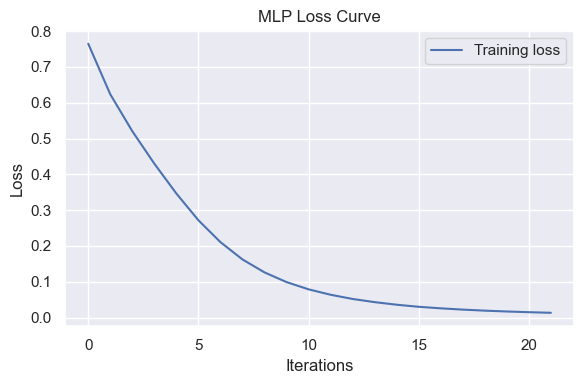

,architecture,test_accuracy
0,"(8,)",0.907621
1,"(16,)",0.914550
2,"(32,)",0.919169
3,"(16, 8)",0.868360
4,"(32, 16)",0.956120
5,"(64, 32, 16)",0.976905


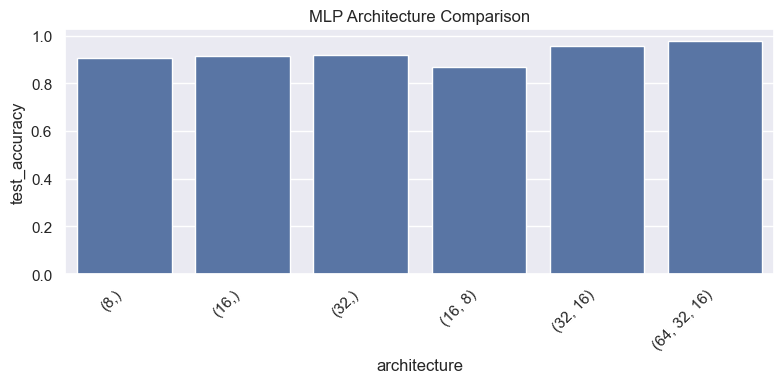

Prediction probabilities (first 5 samples):
      human   nothing
0  0.975414  0.024586
1  0.945293  0.054707
2  0.697955  0.302045
3  0.940087  0.059913
4  0.891111  0.108889
Predicted labels: ['human' 'human' 'human' 'human' 'human']
Saved best MLP model as neural_network.pkl with architecture (64, 32, 16)


In [19]:

# Create and train default MLP per spec
mlp = MLPClassifier(hidden_layer_sizes=(32,16,8), activation='relu', max_iter=1000,
                    early_stopping=True, n_iter_no_change=10, random_state=42)
mlp.fit(X_train, y_train)

# Evaluate
training_accuracy = mlp.score(X_train, y_train)
test_accuracy = mlp.score(X_test, y_test)
print('Training accuracy:', training_accuracy)
print('Test accuracy:', test_accuracy)

y_pred = mlp.predict(X_test)
print('Confusion matrix:', confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=list(le.classes_)))

# Plot training loss curve
if hasattr(mlp, 'loss_curve_'):
    plt.figure(figsize=(6,4))
    plt.plot(mlp.loss_curve_, label='Training loss')
    plt.xlabel('Iterations')
    plt.ylabel('Loss')
    plt.title('MLP Loss Curve')
    plt.legend(); plt.tight_layout(); plt.show()
else:
    print('No loss_curve_ available on this estimator.')

# Architectures sweep
architectures = [(8,), (16,), (32,), (16, 8), (32, 16), (64, 32, 16)]
results = []
for arch in architectures:
    m = MLPClassifier(hidden_layer_sizes=arch, activation='relu', max_iter=1000,
                      early_stopping=True, n_iter_no_change=10, random_state=42)
    m.fit(X_train, y_train)
    acc = m.score(X_test, y_test)
    results.append({'architecture': arch, 'test_accuracy': acc})
res_df = pd.DataFrame(results)
display(res_df)
plt.figure(figsize=(8,4));
sns.barplot(x=res_df['architecture'].astype(str), y='test_accuracy', data=res_df)
plt.xticks(rotation=45, ha='right'); plt.title('MLP Architecture Comparison'); plt.tight_layout(); plt.show()

# Prediction probabilities
probs = mlp.predict_proba(X_test[:5])
print('Prediction probabilities (first 5 samples):')
print(pd.DataFrame(probs, columns=le.classes_))
print('Predicted labels:', le.inverse_transform(mlp.predict(X_test[:5])))

# Save best model
best = max(results, key=lambda r: r['test_accuracy'])
best_model = MLPClassifier(hidden_layer_sizes=best['architecture'], activation='relu', max_iter=1000,
                           early_stopping=True, n_iter_no_change=10, random_state=42)
best_model.fit(np.vstack([X_train,X_test]), np.hstack([y_train,y_test]))
import joblib
joblib.dump(best_model, os.path.join('..','models','neural_network.pkl'))
print('Saved best MLP model as neural_network.pkl with architecture', best['architecture'])


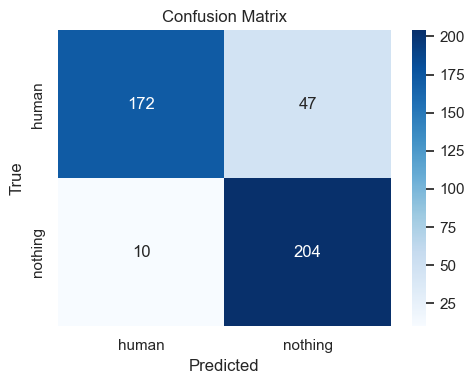

              precision    recall  f1-score   support

       human       0.95      0.79      0.86       219
     nothing       0.81      0.95      0.88       214

    accuracy                           0.87       433
   macro avg       0.88      0.87      0.87       433
weighted avg       0.88      0.87      0.87       433



In [5]:

# Confusion Matrix - Visualize mistakes
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(le.classes_), yticklabels=list(le.classes_))
plt.title('Confusion Matrix')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()
print(classification_report(y_test, y_pred, target_names=list(le.classes_)))
